Arquivos encontrados no workspace: ['/workspaces/Projetos/Projeto Churn/Projeto Churn/data - arq de dados/Telco-Customer-Churn.csv']

Sucesso! Dataset carregado a partir de: /workspaces/Projetos/Projeto Churn/Projeto Churn/data - arq de dados/Telco-Customer-Churn.csv

=== Resumo Estatístico das Variáveis Numéricas ===
       SeniorCitizen       tenure  MonthlyCharges  TotalCharges        Churn
count    7043.000000  7043.000000     7043.000000   7043.000000  7043.000000
mean        0.162147    32.371149       64.761692   2281.916928     0.265370
std         0.368612    24.559481       30.090047   2265.270398     0.441561
min         0.000000     0.000000       18.250000     18.800000     0.000000
25%         0.000000     9.000000       35.500000    402.225000     0.000000
50%         0.000000    29.000000       70.350000   1397.475000     0.000000
75%         0.000000    55.000000       89.850000   3786.600000     1.000000
max         1.000000    72.000000      118.750000   8684.800000 

/tmp/ipykernel_38658/2345050381.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Contract', y='Churn', data=df_clean, errorbar=None, palette='Blues_d')


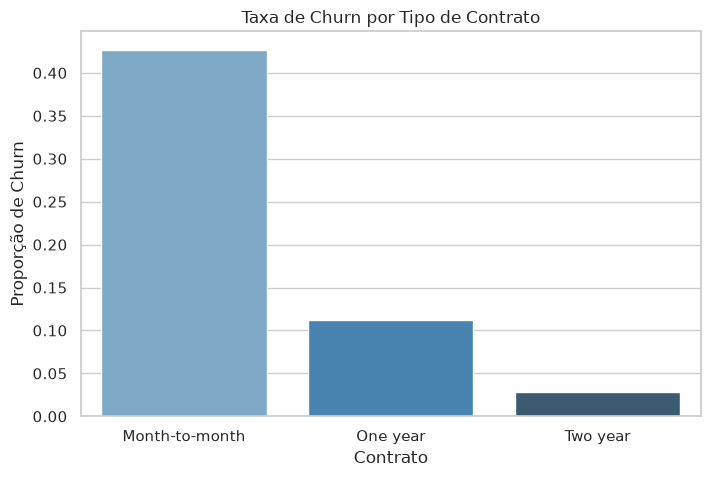


Dataset limpo salvo com sucesso em: /workspaces/projeto_tian/data/processed/churn_processed.csv


In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações de exibição
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

# 1. Procurar em TODA a estrutura do Codespaces
# Busca qualquer arquivo .csv ou .csv.csv existente
arquivos = glob.glob('/workspaces/**/*.csv*', recursive=True)

# Filtrar arquivos processados se existirem
arquivos_dados = [f for f in arquivos if 'processed' not in f and 'ipynb_checkpoints' not in f]

print("Arquivos encontrados no workspace:", arquivos_dados)

if arquivos_dados:
    caminho_csv = arquivos_dados[0]
    df = pd.read_csv(caminho_csv)
    print(f"\nSucesso! Dataset carregado a partir de: {caminho_csv}")
else:
    raise FileNotFoundError("Nenhum arquivo CSV foi encontrado no workspace. Verifique o upload na barra lateral.")

# 2. Tratamento e Limpeza de Dados
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
df_clean = df.drop(columns=['customerID'])
df_clean['Churn'] = df_clean['Churn'].map({'Yes': 1, 'No': 0})

# 3. Análise Exploratória (EDA)
print("\n=== Resumo Estatístico das Variáveis Numéricas ===")
print(df_clean.describe())

print("\n=== Taxa Geral de Churn (%) ===")
print(df_clean['Churn'].value_counts(normalize=True) * 100)

# Gráfico
plt.figure(figsize=(8, 5))
sns.barplot(x='Contract', y='Churn', data=df_clean, errorbar=None, palette='Blues_d')
plt.title('Taxa de Churn por Tipo de Contrato')
plt.ylabel('Proporção de Churn')
plt.xlabel('Contrato')

# Pasta de destino
os.makedirs('/workspaces/projeto_tian/data/processed', exist_ok=True)

plt.savefig('/workspaces/projeto_tian/data/churn_por_contrato.png')
plt.show()

# 4. Salvar Dataset Tratado
caminho_destino = '/workspaces/projeto_tian/data/processed/churn_processed.csv'
df_clean.to_csv(caminho_destino, index=False)
print(f"\nDataset limpo salvo com sucesso em: {caminho_destino}")

